# RNN and LSTM

We will use one sentence throughout:

> **"Rahul lives in Bangalore and he works as a data scientist."**

Our question is: **How can a sequence model use earlier words when processing a later word such as "he"?**

## 1. Start with a sequence

A sequence is data in which order matters.

Examples:
- Text: `Rahul` → `lives` → `in` → `Bangalore`
- Sensor readings: 100 → 110 → 105 → 130
- Audio: one short audio frame followed by the next frame

For our sentence, each word is one **time step** (also called a sequence position).

| Time step | Input word |
|---:|---|
| 1 | Rahul |
| 2 | lives |
| 3 | in |
| 4 | Bangalore |
| 5 | and |
| 6 | he |
| 7 | works |
| 8 | as |
| 9 | a |
| 10 | data |
| 11 | scientist |

Here, *time step* does not have to mean clock time. In text, it means word position. In hourly forecasting, it could mean one hour.

## 2. Why not use an ordinary feed-forward ANN?

A conventional feed-forward ANN can process a representation of an input, but it does not automatically carry a state from one word to the next.

If we feed each word independently, the model does not automatically know that `he` appeared after `Rahul`.

A sequence model needs a mechanism to carry context forward.

That is the central idea of an RNN.

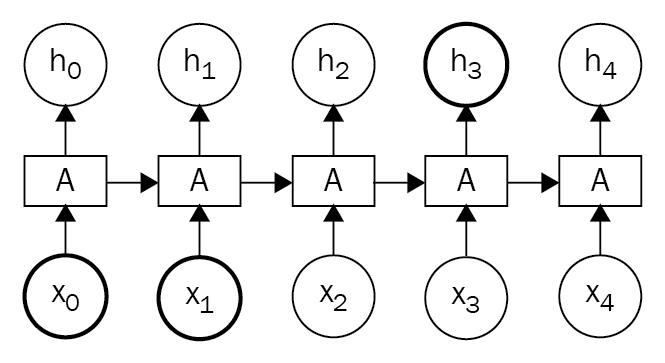

## 3. Read the RNN diagram before reading the equations

First learn the visual vocabulary:

- `xₜ`: the input at the current time step.
- `hₜ₋₁`: the hidden state coming from the previous time step.
- `hₜ`: the new hidden state produced at the current time step.
- `A`: a common label for the RNN cell. It is the same cell reused at each step.
- Horizontal arrows: carry the hidden state forward.
- Vertical arrows: bring the current input into the cell.

The diagram is **unrolled through time**: one recurrent cell is drawn several times so that we can see what happens at successive steps. These are not separate networks with separate weights.

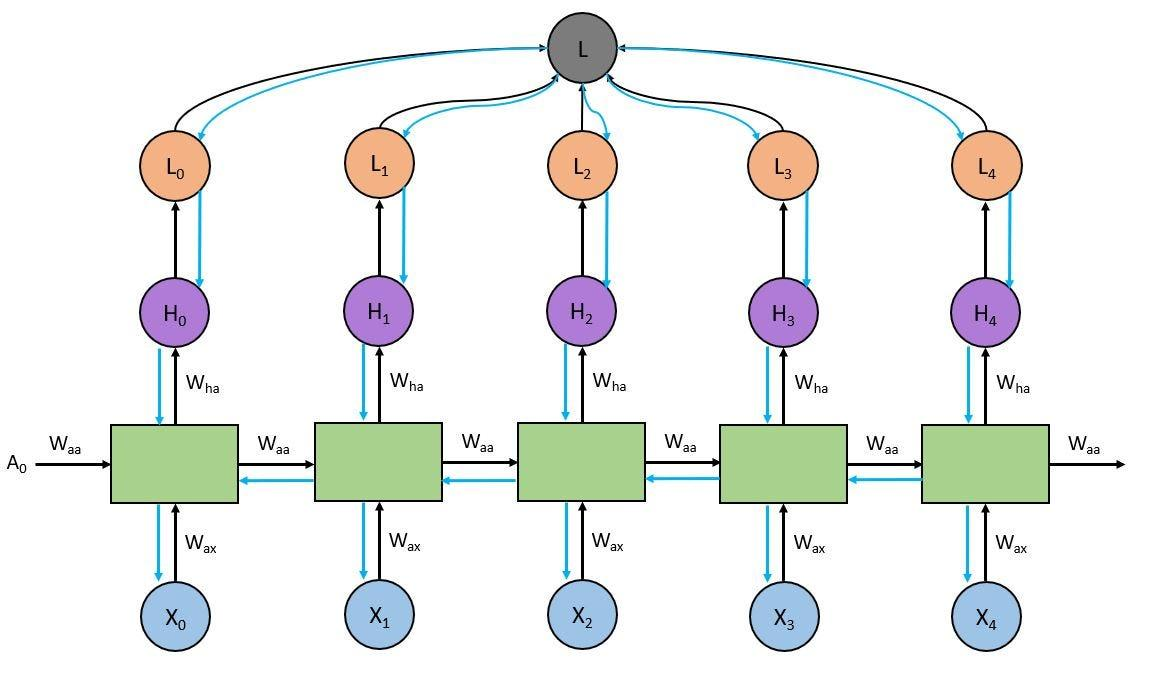

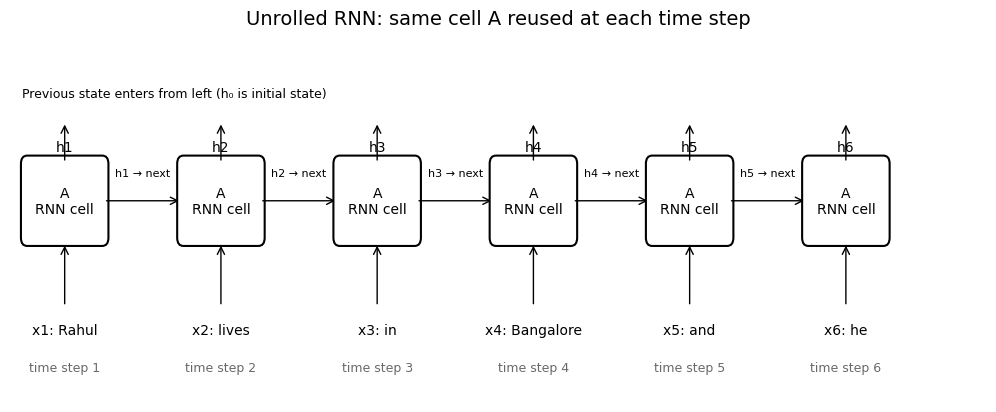

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def draw_rnn_unrolled(words):
    n = len(words)
    fig, ax = plt.subplots(figsize=(max(11, n * 2.1), 4.8))
    ax.set_xlim(-0.7, n * 2.0 - 0.2)
    ax.set_ylim(-1.25, 2.35)
    ax.axis("off")

    xs = [i * 2.0 for i in range(n)]
    for i, (x, word) in enumerate(zip(xs, words), start=1):
        cell = FancyBboxPatch((x - 0.48, 0.35), 0.96, 0.72,
                              boxstyle="round,pad=0.08", linewidth=1.5,
                              edgecolor="black", facecolor="white")
        ax.add_patch(cell)
        ax.text(x, 0.71, "A\nRNN cell", ha="center", va="center", fontsize=10)
        ax.text(x, -0.55, f"x{i}: {word}", ha="center", va="center", fontsize=10)
        ax.add_patch(FancyArrowPatch((x, -0.32), (x, 0.30),
                                     arrowstyle="->", mutation_scale=13))
        ax.text(x, 1.23, f"h{i}", ha="center", va="center", fontsize=10)
        ax.add_patch(FancyArrowPatch((x, 1.08), (x, 1.48),
                                     arrowstyle="->", mutation_scale=13))
        if i < n:
            ax.add_patch(FancyArrowPatch((x + 0.50, 0.71), (xs[i] - 0.50, 0.71),
                                         arrowstyle="->", mutation_scale=13))
            ax.text((x + xs[i]) / 2, 0.95, f"h{i} → next", ha="center", fontsize=8)
        ax.text(x, -0.95, f"time step {i}", ha="center", fontsize=9, color="dimgray")

    ax.text(-0.55, 1.75, "Previous state enters from left (h₀ is initial state)",
            ha="left", va="center", fontsize=9)
    ax.set_title("Unrolled RNN: same cell A reused at each time step", fontsize=14)
    plt.show()

draw_rnn_unrolled(["Rahul", "lives", "in", "Bangalore", "and", "he"])

## 4. The RNN equation — now the notation has a meaning

A common vanilla RNN equation is:

\[
h_t = \tanh(W_{xh}x_t + W_{hh}h_{t-1} + b_h)
\]

Read it in words:

**new hidden state = activation(current input contribution + previous-memory contribution + bias)**

| Symbol | Meaning |
|---|---|
| \(t\) | Current time step / sequence position |
| \(x_t\) | Current input vector |
| \(h_{t-1}\) | Previous hidden-state vector |
| \(W_{xh}\) | Weights from input to hidden state |
| \(W_{hh}\) | Recurrent weights from previous hidden state |
| \(b_h\) | Bias |
| \(\tanh\) | Activation function |
| \(h_t\) | New hidden-state vector |

For our sentence at time step 2:

\[
h_2 = \tanh(W_{xh}x_2 + W_{hh}h_1 + b_h)
\]

Here, `x₂` represents the vector for **lives**, and `h₁` is the state produced after **Rahul**.

The same weight matrices are reused at time steps 1, 2, 3, and so on.

If the task requires an output at each step, a typical output layer is:

\[
y_t = W_{hy}h_t + b_y
\]

A classification model may then apply softmax. Some sequence tasks use only the final hidden state; others produce an output at every time step.

## 5. Why can a vanilla RNN struggle with long sequences?

During training, the model uses **backpropagation through time (BPTT)**. The learning signal travels backwards through the unrolled time steps.

When gradients are repeatedly multiplied by values whose magnitudes are small, they can shrink dramatically. This is the **vanishing-gradient problem**.

Intuition:
- A clue near the beginning of a long sequence may need to influence a decision near the end.
- The learning signal sent back to early time steps can become very small.
- The RNN may struggle to learn that long-range relationship.

This is not the same as saying an RNN always forgets a word during every forward pass. The core issue is that training can struggle to learn and preserve long-range dependencies.

# Part 2 — LSTM

## 6. Why introduce LSTM?

LSTM stands for **Long Short-Term Memory**. It is a type of recurrent neural network designed to make learning long-range dependencies easier.

The key architectural difference:

- Vanilla RNN: carries a hidden state \(h_t\).
- LSTM: carries both a hidden state \(h_t\) and a cell state \(C_t\).

A useful mental model:
- **Cell state \(C_t\):** the memory pathway carried through the sequence.
- **Hidden state \(h_t\):** the current representation exposed by the cell and passed forward.

This is an analogy, not a claim that the cell state stores words in readable form.

## 7. First read one LSTM cell — identify the inputs and outputs

At time step \(t\), a standard LSTM cell receives three things:

1. Current input \(x_t\)
2. Previous hidden state \(h_{t-1}\)
3. Previous cell state \(C_{t-1}\)

It produces two things:

1. New hidden state \(h_t\)
2. New cell state \(C_t\)

The three gates are:
- Forget gate: controls how much of the previous cell state is retained.
- Input gate: controls how much candidate information is added.
- Output gate: controls how much of the updated cell state is exposed as the hidden state.

The gate names describe their roles. They do not mean the network makes human-like conscious decisions.

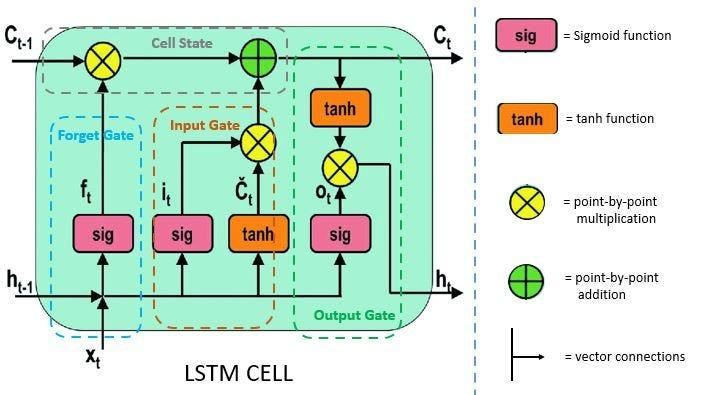

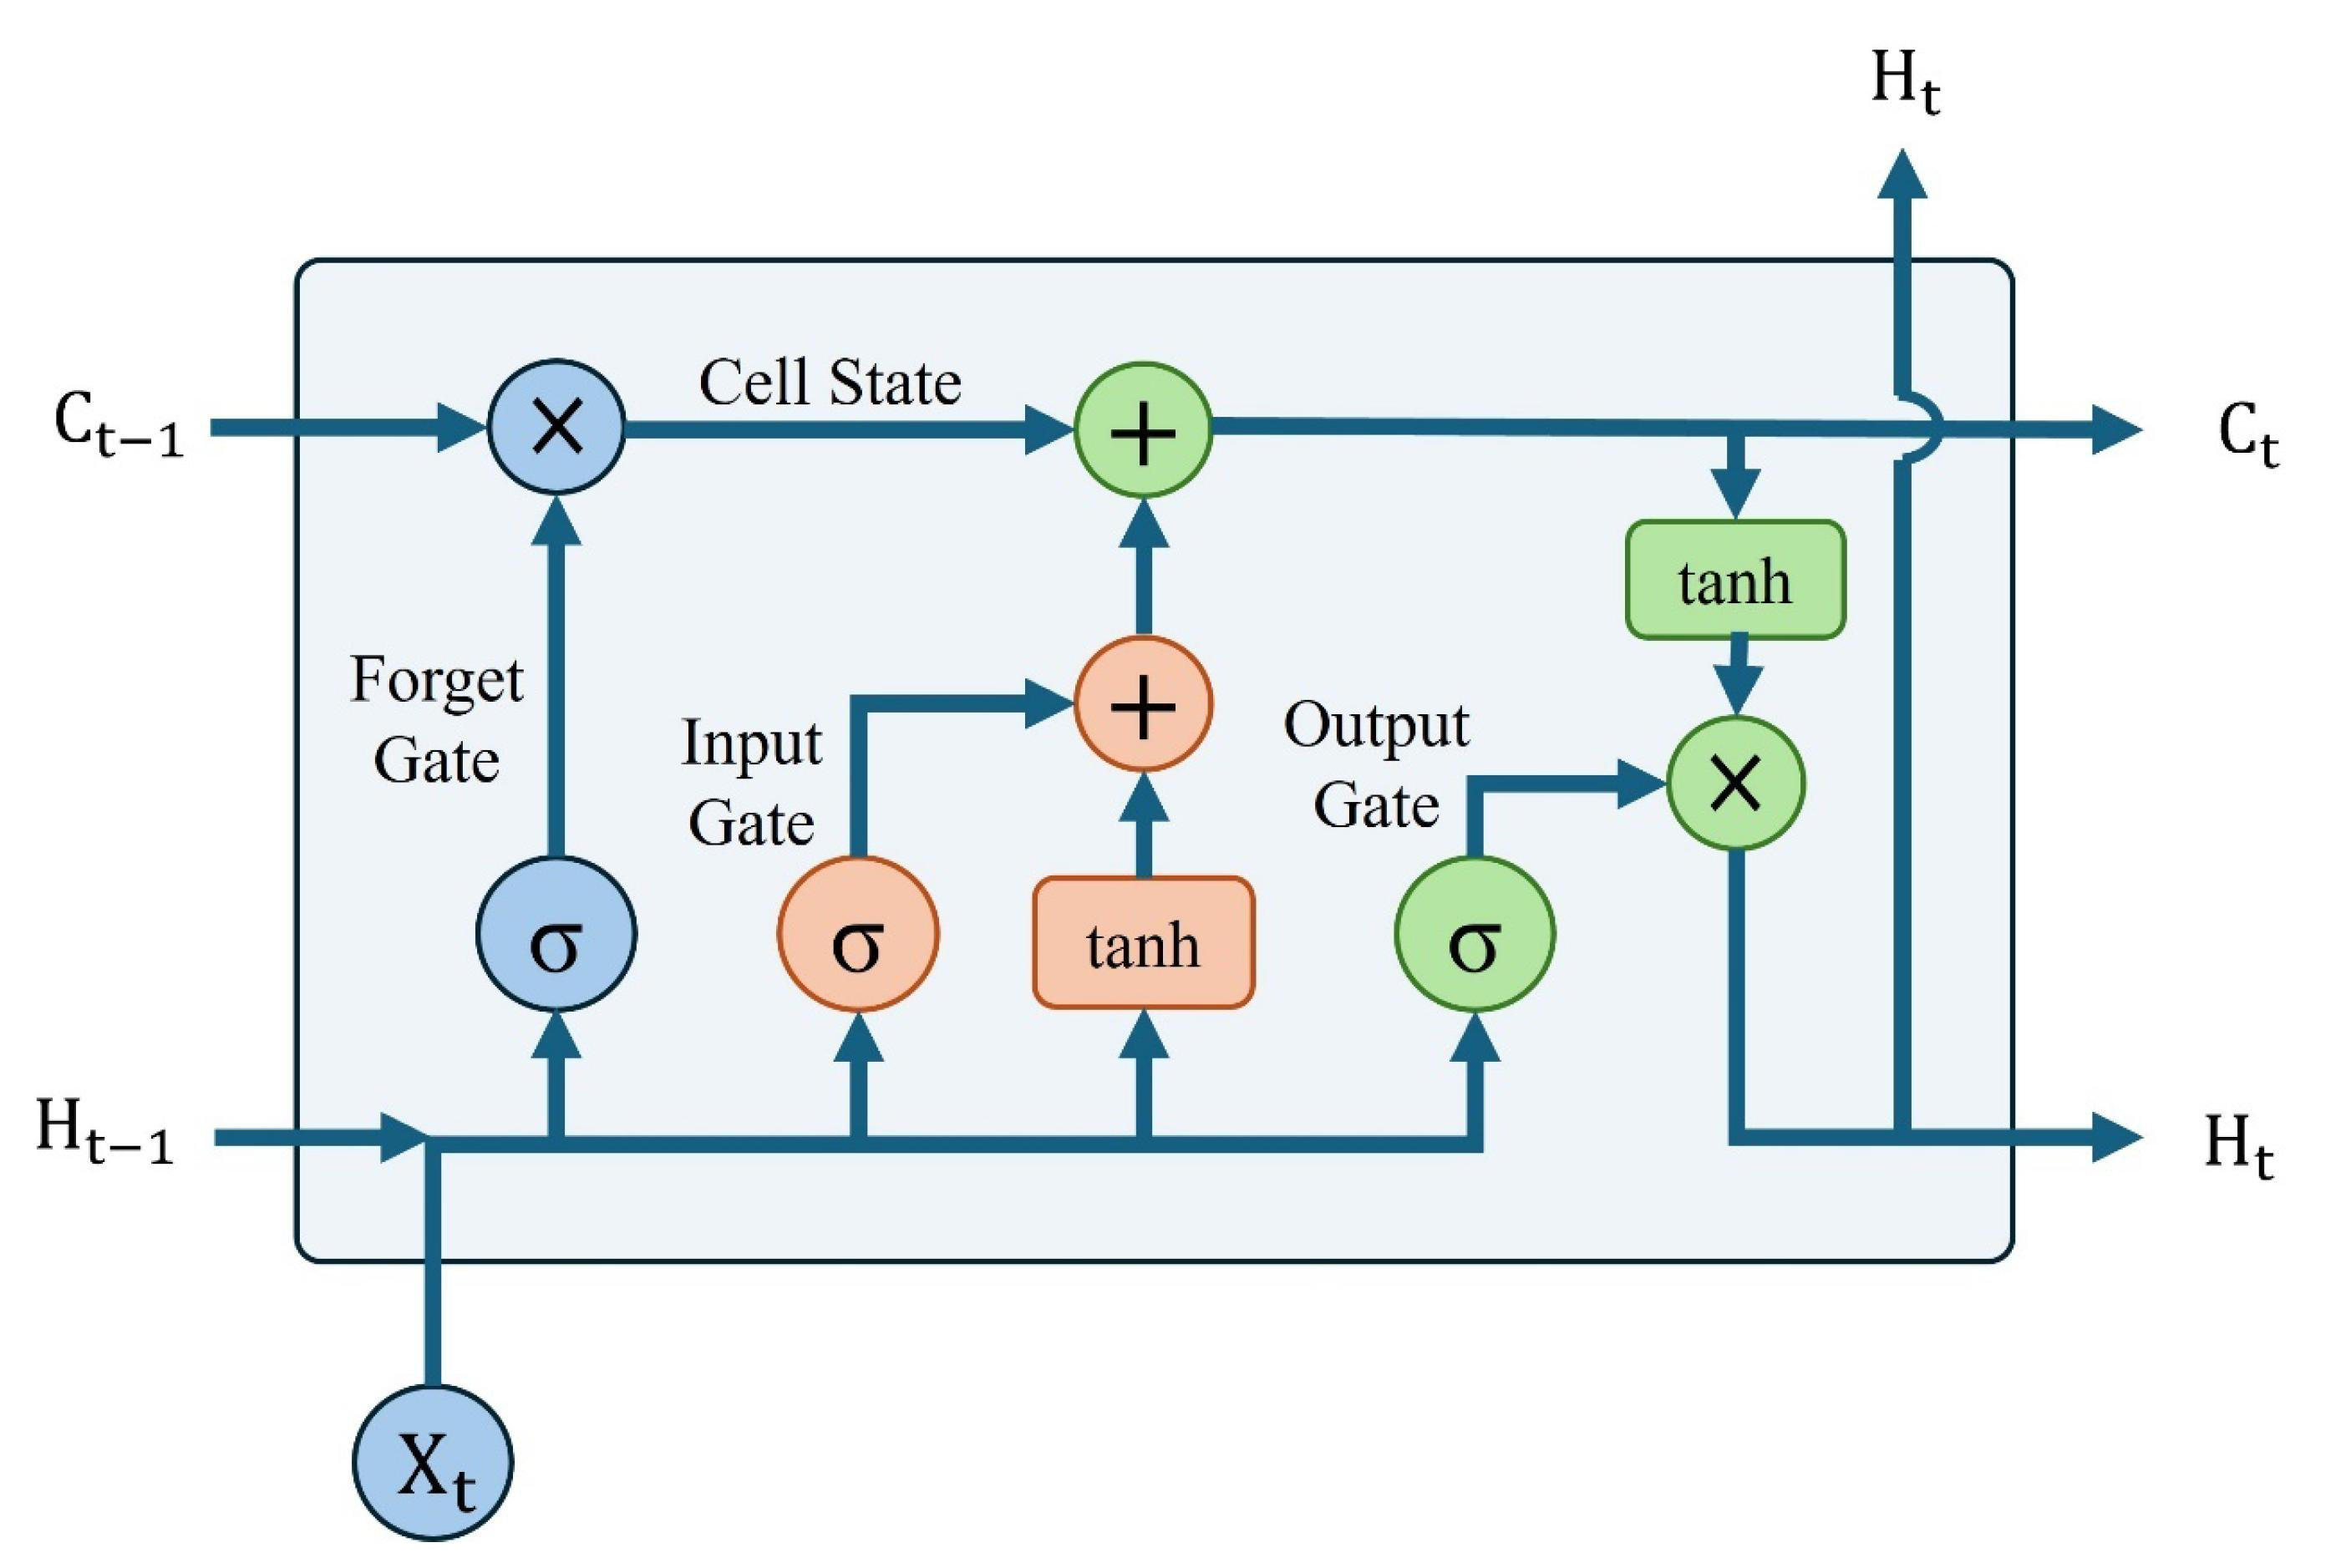

### How to read the LSTM cell

Do not try to follow every arrow at once. Read it in this order:

**A. Inputs on the left**
- `xₜ`: the current word, such as **he**.
- `hₜ₋₁`: the previous context.
- `Cₜ₋₁`: the previous cell memory.

**B. Forget gate**
- Receives the current input and previous hidden state.
- Produces values between 0 and 1 using sigmoid.
- Those values multiply the previous cell state.
- A value near 1 retains that component; a value near 0 removes much of it.

**C. Input gate and candidate memory**
- Input gate uses sigmoid to control how much new candidate information is added.
- Candidate-memory branch uses tanh to create candidate values.
- Their element-wise product is the selected new information.

**D. Cell-state update**
- Retained old memory and selected new memory are added.
- The result is the new cell state \(C_t\).

**E. Output gate**
- The updated cell state is passed through tanh.
- The output gate controls how much of that transformed state becomes the new hidden state \(h_t\).

The exact layout varies between textbooks. Follow the labels and arrows, not the physical position of a gate on the page.

## 8. Use our sentence to follow one LSTM time step at a time

We return to the same sentence:

**Rahul → lives → in → Bangalore → and → he → works → as → a → data → scientist**

| Step | Current input | Previous states received | New states produced |
|---:|---|---|---|
| 1 | Rahul | \(h_0, C_0\) | \(h_1, C_1\) |
| 2 | lives | \(h_1, C_1\) | \(h_2, C_2\) |
| 3 | in | \(h_2, C_2\) | \(h_3, C_3\) |
| 4 | Bangalore | \(h_3, C_3\) | \(h_4, C_4\) |
| 5 | and | \(h_4, C_4\) | \(h_5, C_5\) |
| 6 | he | \(h_5, C_5\) | \(h_6, C_6\) |

At step 6:
- \(x_6\) is the vector for the word **he**.
- \(h_5\) is the previous hidden state.
- \(C_5\) is the previous cell state.
- The gates update the memory.
- The cell produces \(C_6\) and \(h_6\).

The model may learn that the earlier name Rahul is relevant to interpreting “he”. This is learned from examples; it is not a hard-coded pronoun rule.

## 9. First understand the LSTM recurrence — just like we did for RNN

Before opening the six gate equations, write the overall operation in one line.

For a vanilla RNN, the recurrence is:

\[
\boxed{h_t = f(x_t,h_{t-1})}
\]

For example, at time step 2:

\[
\boxed{h_2 = f(x_2,h_1)}
\]

Read this carefully:
- \(x_2\) is the **current input** (the word `lives`).
- \(h_1\) is the **previous hidden state** (context produced after `Rahul`).
- \(h_2\) is the **new hidden state** produced after processing `lives`.

A small notation correction: we do **not** write \(x_2=f(x_1,h_1)\). The input \(x_2\) is already given by the sequence. The network uses \(x_2\) and \(h_1\) to calculate \(h_2\).

### What changes in LSTM?

LSTM carries **two previous states**, not just one:
- Previous hidden state: \(h_{t-1}\)
- Previous cell state: \(C_{t-1}\)

It also receives the current input \(x_t\).

So its overall recurrence is:

\[
\boxed{(h_t,C_t)=F(x_t,h_{t-1},C_{t-1})}
\]

Here, \(F\) simply means “the complete LSTM cell operation”, including its gates.

For our sentence, at time step 2:

\[
\boxed{(h_2,C_2)=F(x_2,h_1,C_1)}
\]

Read it in plain English:

> “To process the word `lives`, the LSTM takes the current input `lives`, the previous hidden state created after `Rahul`, and the previous cell state. It processes all three and produces a new hidden state and a new cell state.”

### Follow the same pattern across the sentence

| Time step | Current input | What enters the LSTM | What comes out |
|---:|---|---|---|
| 1 | Rahul (\(x_1\)) | \(x_1,h_0,C_0\) | \(h_1,C_1\) |
| 2 | lives (\(x_2\)) | \(x_2,h_1,C_1\) | \(h_2,C_2\) |
| 3 | in (\(x_3\)) | \(x_3,h_2,C_2\) | \(h_3,C_3\) |
| 4 | Bangalore (\(x_4\)) | \(x_4,h_3,C_3\) | \(h_4,C_4\) |
| 5 | and (\(x_5\)) | \(x_5,h_4,C_4\) | \(h_5,C_5\) |
| 6 | he (\(x_6\)) | \(x_6,h_5,C_5\) | \(h_6,C_6\) |

Notice the repeating pattern:

\[
(x_1,h_0,C_0)\rightarrow(h_1,C_1)
\]

\[
(x_2,h_1,C_1)\rightarrow(h_2,C_2)
\]

\[
(x_3,h_2,C_2)\rightarrow(h_3,C_3)
\]

The same LSTM cell and its learned weights are reused at every time step.

### Compare the two recurrence patterns

| Vanilla RNN | LSTM |
|---|---|
| \(h_t=f(x_t,h_{t-1})\) | \((h_t,C_t)=F(x_t,h_{t-1},C_{t-1})\) |
| Receives current input + previous hidden state | Receives current input + previous hidden state + previous cell state |
| Produces one state: \(h_t\) | Produces two states: \(h_t,C_t\) |

**This is the key bridge from RNN to LSTM:** LSTM has an additional state, the Cell State, and gates that control how that state is updated.

Now that the overall input-output relationship is clear, let's open the LSTM cell and see how it calculates those two outputs.

## 10. Open the LSTM recurrence: how does it calculate \(h_2\) and \(C_2\)?

We just wrote:

\[
(h_2,C_2)=F(x_2,h_1,C_1)
\]

This is the high-level view. The function \(F\) is made up of six calculations.

At time step 2 in our sentence:
- \(x_2\) = the vector representing `lives`
- \(h_1\) = the hidden state produced after `Rahul`
- \(C_1\) = the cell state produced after `Rahul`

The LSTM uses these to calculate its gates and then produce \(C_2\) and \(h_2\).

### Step 1 — Forget Gate: what should happen to the previous cell state?

\[
f_2=\sigma(W_f[h_1,x_2]+b_f)
\]

The Forget Gate calculates values between 0 and 1. These values control how much of each component of \(C_1\) is retained.

\[
\text{Retained memory}=f_2\odot C_1
\]

### Step 2 — Input Gate: how much candidate information should be added?

\[
i_2=\sigma(W_i[h_1,x_2]+b_i)
\]

This controls how much candidate information should enter the cell state.

### Step 3 — Candidate memory: what new information could be stored?

\[
\tilde C_2=\tanh(W_C[h_1,x_2]+b_C)
\]

This creates candidate memory using the current input and previous hidden state.

The selected new information is:

\[
\text{Selected new memory}=i_2\odot\tilde C_2
\]

### Step 4 — Update the Cell State

Now combine the retained old memory and selected new memory:

\[
\boxed{C_2=f_2\odot C_1+i_2\odot\tilde C_2}
\]

This is how the LSTM calculates its new cell state \(C_2\).

### Step 5 — Output Gate: what part of the updated memory should be exposed?

\[
o_2=\sigma(W_o[h_1,x_2]+b_o)
\]

The Output Gate controls how much of the transformed cell state contributes to the hidden state.

### Step 6 — Calculate the new Hidden State

\[
\boxed{h_2=o_2\odot\tanh(C_2)}
\]

Now we have both outputs:

- \(C_2\): updated cell state
- \(h_2\): updated hidden state

Therefore, the high-level operation is complete:

\[
\boxed{(h_2,C_2)=F(x_2,h_1,C_1)}
\]

### Put the six calculations in the correct order

| Order | Calculation | Result |
|---:|---|---|
| 1 | Forget Gate | \(f_2\) |
| 2 | Input Gate | \(i_2\) |
| 3 | Candidate memory | \(\tilde C_2\) |
| 4 | Cell State update | \(C_2\) |
| 5 | Output Gate | \(o_2\) |
| 6 | Hidden State update | \(h_2\) |

## 11. Transfer the same idea to time-series data

Now change the input domain. Instead of words, suppose we have daily electricity consumption:

| Time step | Day | Consumption (kWh) |
|---:|---|---:|
| 1 | Monday | 100 |
| 2 | Tuesday | 110 |
| 3 | Wednesday | 105 |
| 4 | Thursday | 130 |
| 5 | Friday | 150 |
| 6 | Saturday | 170 |

The model receives one observation at each time step. It can use the current value and information carried from earlier observations to help predict the next value (Sunday).

The architecture is the same:
- \(x_t\) is now a numerical feature vector for that time step, rather than a word embedding.
- RNN carries \(h_t\).
- LSTM carries \(h_t\) and \(C_t\).

The input could contain more than consumption: temperature, day of week, holiday indicator, and other features can be included in the input vector.

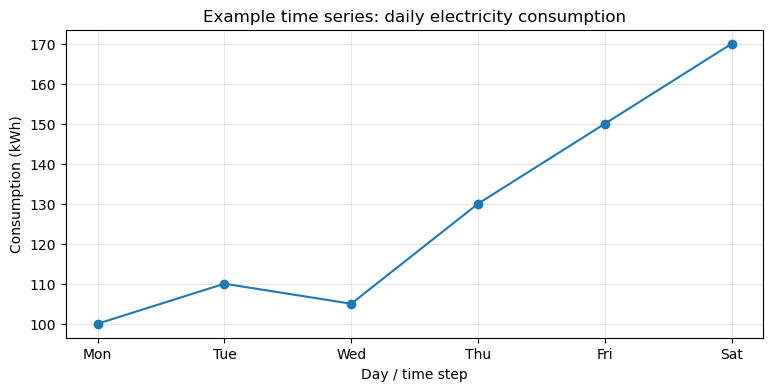

In [4]:
import matplotlib.pyplot as plt

days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
consumption = [100, 110, 105, 130, 150, 170]

plt.figure(figsize=(9, 4))
plt.plot(days, consumption, marker="o")
plt.title("Example time series: daily electricity consumption")
plt.xlabel("Day / time step")
plt.ylabel("Consumption (kWh)")
plt.grid(True, alpha=0.3)
plt.show()

## 12. RNN vs LSTM — the final comparison

| Feature | Vanilla RNN | LSTM |
|---|---|---|
| State carried forward | Hidden state \(h_t\) | Hidden state \(h_t\) and cell state \(C_t\) |
| Gates | No | Forget, input, output |
| Long-range dependencies | Can be difficult to learn | Designed to make them easier to learn |
| Architecture | Simpler | More elaborate |
| Vanishing gradients | More susceptible | Helps mitigate the problem |

LSTM does not eliminate every training difficulty or guarantee that it will remember every important detail. It provides a better mechanism for learning longer dependencies in many sequence tasks.

Modern NLP often uses Transformer architectures, but RNNs and LSTMs remain valuable for understanding sequence modelling and are still useful in selected applications.

## 13. Quick verbal recap — explain without looking at the equations

**RNN:** “At each time step, the RNN receives the current input and the previous hidden state. It combines them to create a new hidden state. That state is passed to the next time step. The same cell and weights are reused across the sequence.”

**LSTM:** “At each time step, LSTM receives the current input, previous hidden state and previous cell state. The forget gate controls what old cell information is retained. The input gate controls what candidate information is added. The output gate controls what part of the updated cell state is exposed as the hidden state. Both the new cell state and new hidden state are passed to the next time step.”

### Check your understanding

1. In the RNN diagram, what does `A` mean?
2. In \(h_{t-1}\), what does \(t-1\) identify?
3. In an LSTM, what are the three inputs at time step \(t\)?
4. Which gate controls the retention of previous cell-state information?
5. What does the plus sign in the cell-state update equation combine?
6. In a time-series task, what could \(x_t\) represent?

### Answers
1. The recurrent cell, reused at each time step.
2. The immediately previous sequence position.
3. Current input \(x_t\), previous hidden state \(h_{t-1}\), and previous cell state \(C_{t-1}\).
4. Forget gate.
5. Retained old memory and selected candidate new memory.
6. The current observation or feature vector, such as electricity usage and other measurements.

# Bidirectional LSTM (BiLSTM)

## 1. Why do we need Bidirectional LSTM?

So far, we have studied a standard LSTM. It processes a sequence in one direction: from left to right.

Consider this sentence:

"The movie was not good."

A standard LSTM reads the sentence in this order:

Forward direction

The

movie

was

not

good

Reading direction

As it processes each word, it uses the information from the words it has already encountered.

For example:

- When processing `The`, it has no information about the remaining words.
- When processing `movie`, it knows `The`.
- When processing `not`, it knows `The movie was`.
- When processing `good`, it knows the complete preceding context.

But consider a situation where we want to understand a word using both the words before it and the words after it.

Wouldn't it be useful to process the sentence in the opposite direction as well?

That's exactly the idea behind Bidirectional LSTM.

## 2. What is Bidirectional LSTM?

A Bidirectional LSTM uses two separate LSTM networks to process the same input sequence in opposite directions.

1. Forward LSTM: processes the sequence from left to right.
2. Backward LSTM: processes the sequence from right to left.

Their outputs are then combined to produce a representation containing information from both directions.

Let's understand this using our sentence.

Input:

"The movie was not good."

Forward LSTM reads:

The --> movie --> was \rightarrow not --> good 

Backward LSTM reads:

 good --> not --> was --> movie --> The \\]

Both networks process the same words, but in opposite directions.

## 3. How does it work internally?

Let's understand the two LSTM networks separately.

### A. Forward LSTM

The forward LSTM processes the input sequence in the normal order.

At each time step:

(h_t^f,C_t^f)=LSTM_f(x_t,h\_{t-1}^f,C\_{t-1}^f)

Here:

- \\(x_t\\): current input word representation.
- \\(h\_{t-1}^f\\): previous forward hidden state.
- \\(C\_{t-1}^f\\): previous forward cell state.
- \\(h_t^f\\): updated forward hidden state.
- \\(C_t^f\\): updated forward cell state.

### B. Backward LSTM

The backward LSTM processes the same sequence in reverse order.

Its recurrence can be written as:

\\[ (h_t^b,C_t^b)=LSTM_b(x_t,h\_{t+1}^b,C\_{t+1}^b) \\]

Notice the difference:

- Forward LSTM receives information from the previous position.
- Backward LSTM receives information from the next position in the original sequence.

Both networks have their own independent weights and states.

## 4. How are the two outputs combined?

Once both LSTMs process the sequence, their hidden representations are combined.

The commonly used approach is concatenation.

\\[ h_t=[h_t^f;h_t^b] \\]

Here:

- \\(h_t^f\\): forward hidden representation.
- \\(h_t^b\\): backward hidden representation.
- \\([\\,;\\,]\\): concatenation operation.

Let's take a small numerical example.

Suppose the forward LSTM produces:

\\[ h_t^f=[0.2,0.5,0.8] \\]

And the backward LSTM produces:

\\[ h_t^b=[0.4,0.1,0.7] \\]

After concatenation:

\\[ h_t=[0.2,0.5,0.8,0.4,0.1,0.7] \\]

The resulting representation contains information learned from both directions.

Important: If each LSTM has 64 units, concatenation produces a 128-dimensional representation.

## 5. Why is this useful? Let's understand with sentiment analysis.

Consider these sentences:

1. "The movie was good."
2. "The movie was not good."

The word `good` appears in both sentences, but the overall sentiment is different.

A model needs to understand the context surrounding words, rather than looking at individual words independently.

Bidirectional LSTM can use information from both earlier and later positions in the sequence.

This is particularly useful for:

- Sentiment analysis
- Text classification
- Named Entity Recognition (NER)
- Part-of-speech tagging
- Speech recognition (when the complete utterance is available)

## 6. Standard LSTM vs Bidirectional LSTM

| Feature                             | Standard LSTM              | Bidirectional LSTM                           |
| ----------------------------------- | -------------------------- | -------------------------------------------- |
| Processing direction                | Forward                    | Forward and backward                         |
| Number of recurrent networks        | One                        | Two                                          |
| Context                             | Previous sequence elements | Previous and subsequent sequence elements    |
| Parameters                          | Lower                      | Higher                                       |
| Computational cost                  | Generally lower            | Generally higher                             |
| Real-time forecasting               | Suitable                   | Usually unsuitable for unknown future inputs |
| Whole-text sentiment classification | Suitable                   | Often useful                                 |

## 7. Implementing Bidirectional LSTM using Keras

Keras provides a wrapper called `Bidirectional`.

Instead of creating two LSTM networks manually, we wrap an existing LSTM layer inside it.

```
import tensorflow as tfmodel = tf.keras.Sequential([    # Convert token IDs into dense word vectors    tf.keras.layers.Embedding(        input_dim=10000,        output_dim=64,        mask_zero=True    ),    # Process the sequence in both directions    tf.keras.layers.Bidirectional(        tf.keras.layers.LSTM(64)    ),    # Classification layers    tf.keras.layers.Dense(32, activation="relu"),    tf.keras.layers.Dense(1, activation="sigmoid")])model.compile(    optimizer="adam",    loss="binary_crossentropy",    metrics=["accuracy"])model.summary()
```

Let's understand this important part:

```
tf.keras.layers.Bidirectional(    tf.keras.layers.LSTM(64))
```

- `LSTM(64)` creates an LSTM with 64 units.
- `Bidirectional()` creates forward and backward versions of that LSTM.
- By default, their outputs are concatenated.

Therefore:

\\[ 64+64=128 \\]

The next Dense layer receives 128 features per review.

## 8. An important limitation of Bidirectional LSTM

There is one important consideration.

Suppose we are forecasting tomorrow's temperature using the previous 30 days.

We know the past 30 days, but we don't know tomorrow's temperature.

A backward LSTM processing the known input window can technically run in reverse, but it cannot access the actual future observation we are trying to predict.

Therefore, Bidirectional LSTM does not automatically give us an advantage in future forecasting.

However, in sentiment analysis, the entire review is available before classification.

That's why Bidirectional LSTM is particularly suitable for this problem.

## 9. Final takeaway

Standard LSTM

Reads the sequence in one direction and maintains memory of preceding elements.

Bidirectional LSTM

Reads the same sequence in two directions and combines both representations.

The central idea

Standard LSTM captures preceding context; Bidirectional LSTM captures context from both sides of the sequence.